#                                                **🌹«زَكَاةُ العِلْمِ نَشْرُهُ»🌹**


#                                           **صَلِّ  عَلَى  الْحَبِيبِ   قَلْبِك  يَطِيب  ﷺ**


#                                       **وَمَا تَوْفِيقِي إِلاَّ بِاللَّهِ عَلَيْهِ تَوَكَّلْتُ وَإِلَيْهِ أُنِيبُ**



# ECG Heartbeat Classification — End-to-End Deep Learning Project

**Project goal:** classify preprocessed ECG heartbeat segments into five MIT-BIH classes and compare four model families fairly:

1. Simple RNN
2. LSTM
3. Bidirectional LSTM
4. 1D CNN

The notebook includes data checks, exploratory analysis, a train/validation/test protocol, comparable model training, metrics (Accuracy, Macro Precision/Recall/F1), confusion matrices, learning curves, model export, and generation of a FastAPI + Swagger UI service and a Streamlit GUI.

> **Medical safety:** This is an educational research prototype, not a diagnostic device. Do not use predictions for medical decisions. High accuracy on this preprocessed dataset does not establish clinical safety or generalization to new patients.

## Dataset

Download the Kaggle dataset and place these files in `data/`:

- `mitbih_train.csv`
- `mitbih_test.csv`
- `ptbdb_normal.csv`
- `ptbdb_abnormal.csv`

This notebook's main four-model comparison uses **MIT-BIH only** (five-class task). PTBDB is a separate binary task and is not mixed into the five-class experiment because its labels and dataset source differ.

Each MIT-BIH row is expected to have 187 signal values plus a final class label (188 columns total). The supplied train file is split into train/validation; the supplied test file remains untouched until final evaluation.

## Cell 1 — Install dependencies

Run once in your notebook environment. If you are using an existing environment, restart the kernel if prompted.

In [ ]:
# %pip install -q numpy pandas matplotlib seaborn scikit-learn tensorflow fastapi "uvicorn[standard]" streamlit requests joblib

## Cell 2 — Imports and reproducibility

This cell imports the libraries and fixes random seeds where possible. Deep learning can still have small run-to-run differences depending on hardware and TensorFlow operations.

In [ ]:
from pathlib import Path
import os
import json
import time
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATA_DIR = Path("data")
ARTIFACT_DIR = Path("artifacts")
MODEL_DIR = ARTIFACT_DIR / "models"
ARTIFACT_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
NumPy: 2.5.3
GPU devices: []


## Cell 3 — Check that the dataset files exist

Download the Kaggle ZIP manually, extract it, and put the four CSVs inside the `data` folder beside this notebook. This cell gives a clear error if the required MIT-BIH files are missing.

In [ ]:
required_files = [
    "mitbih_train.csv",
    "mitbih_test.csv",
    "ptbdb_normal.csv",
    "ptbdb_abnormal.csv",
]

missing = [name for name in required_files if not (DATA_DIR / name).exists()]
if missing:
    raise FileNotFoundError(
        "Missing file(s): " + ", ".join(missing) +
        "\nCreate a 'data' folder beside this notebook and place the four CSV files inside it."
    )

print("All four CSV files were found.")

All four CSV files were found.


## Cell 4 — Load and inspect all four files

The first two files belong to the five-class MIT-BIH task. The PTBDB normal/abnormal files form a separate binary task. We inspect all four, but only MIT-BIH is used in the fair four-model comparison below.

In [ ]:
dataframes = {}
for filename in required_files:
    df = pd.read_csv(DATA_DIR / filename, header=None)
    dataframes[filename] = df
    print(f"\n{filename}")
    print("Shape:", df.shape)
    print("Missing values:", int(df.isna().sum().sum()))
    print("Duplicate rows:", int(df.duplicated().sum()))
    print("First row preview:", df.iloc[0, :6].tolist(), "... label =", df.iloc[0, -1])


mitbih_train.csv
Shape: (87554, 188)
Missing values: 0
Duplicate rows: 0
First row preview: [0.9779411554336547, 0.9264705777168274, 0.6813725233078003, 0.24509803950786593, 0.15441176295280457, 0.19117647409439087] ... label = 0.0

mitbih_test.csv
Shape: (21892, 188)
Missing values: 0
Duplicate rows: 0
First row preview: [1.0, 0.7582644820213318, 0.11157024651765823, 0.0, 0.08057851344347, 0.07851240038871765] ... label = 0.0

ptbdb_normal.csv
Shape: (4046, 188)
Missing values: 0
Duplicate rows: 1
First row preview: [1.0, 0.9003241658210753, 0.35858994722366333, 0.051458671689033515, 0.04659643396735191, 0.1268233358860016] ... label = 0.0

ptbdb_abnormal.csv
Shape: (10506, 188)
Missing values: 0
Duplicate rows: 6
First row preview: [0.9322328567504883, 0.8696785569190979, 0.8861859440803527, 0.9296264052391052, 0.9087749719619752, 0.9339704513549805] ... label = 1.0


## Cell 5 — Validate the MIT-BIH structure

Expected shape: 188 columns — 187 signal values and one target label. We check class labels and numeric values before training.

In [ ]:
train_df = dataframes["mitbih_train.csv"].copy()
test_df = dataframes["mitbih_test.csv"].copy()

EXPECTED_SIGNAL_LENGTH = 187
EXPECTED_CLASSES = [0, 1, 2, 3, 4]
CLASS_NAMES = {
    0: "N - Normal",
    1: "S - Supraventricular ectopic",
    2: "V - Ventricular ectopic",
    3: "F - Fusion beat",
    4: "Q - Unknown/unclassifiable",
}

for name, df in [("train", train_df), ("test", test_df)]:
    if df.shape[1] != EXPECTED_SIGNAL_LENGTH + 1:
        raise ValueError(f"{name} should have 188 columns, found {df.shape[1]}.")
    if df.isna().any().any():
        raise ValueError(f"{name} contains missing values. Inspect before training.")
    if not np.isfinite(df.to_numpy(dtype=np.float64)).all():
        raise ValueError(f"{name} contains non-finite values.")
    labels = set(df.iloc[:, -1].astype(int).unique())
    if not labels.issubset(set(EXPECTED_CLASSES)):
        raise ValueError(f"Unexpected labels in {name}: {labels}")

print("Structure checks passed.")
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Training labels:", sorted(train_df.iloc[:, -1].astype(int).unique()))

Structure checks passed.
Train shape: (87554, 188)
Test shape: (21892, 188)
Training labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


## Cell 6 — Explore class imbalance

Class imbalance means some labels occur much more often than others. This is why accuracy alone is not enough; we also report macro F1 and per-class recall.

,class_id,class_name,count,percentage
0,0,N - Normal,72471,82.77
1,1,S - Supraventricular ectopic,2223,2.54
2,2,V - Ventricular ectopic,5788,6.61
3,3,F - Fusion beat,641,0.73
4,4,Q - Unknown/unclassifiable,6431,7.35


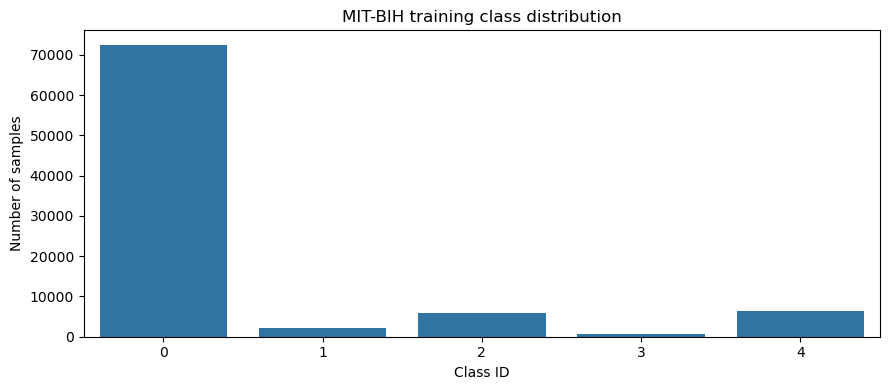

In [ ]:
train_counts = train_df.iloc[:, -1].astype(int).value_counts().sort_index()
display(pd.DataFrame({
    "class_id": train_counts.index,
    "class_name": [CLASS_NAMES[int(i)] for i in train_counts.index],
    "count": train_counts.values,
    "percentage": ((train_counts.values / train_counts.sum() * 100).round(2)),
}))

plt.figure(figsize=(9, 4))
sns.barplot(x=train_counts.index.astype(str), y=train_counts.values)
plt.title("MIT-BIH training class distribution")
plt.xlabel("Class ID")
plt.ylabel("Number of samples")
plt.tight_layout()
plt.show()

## Cell 7 — Plot example ECG signals

Each row contains 187 ordered signal values. These plots help confirm that the rows are waveform-like sequences rather than ordinary tabular features.

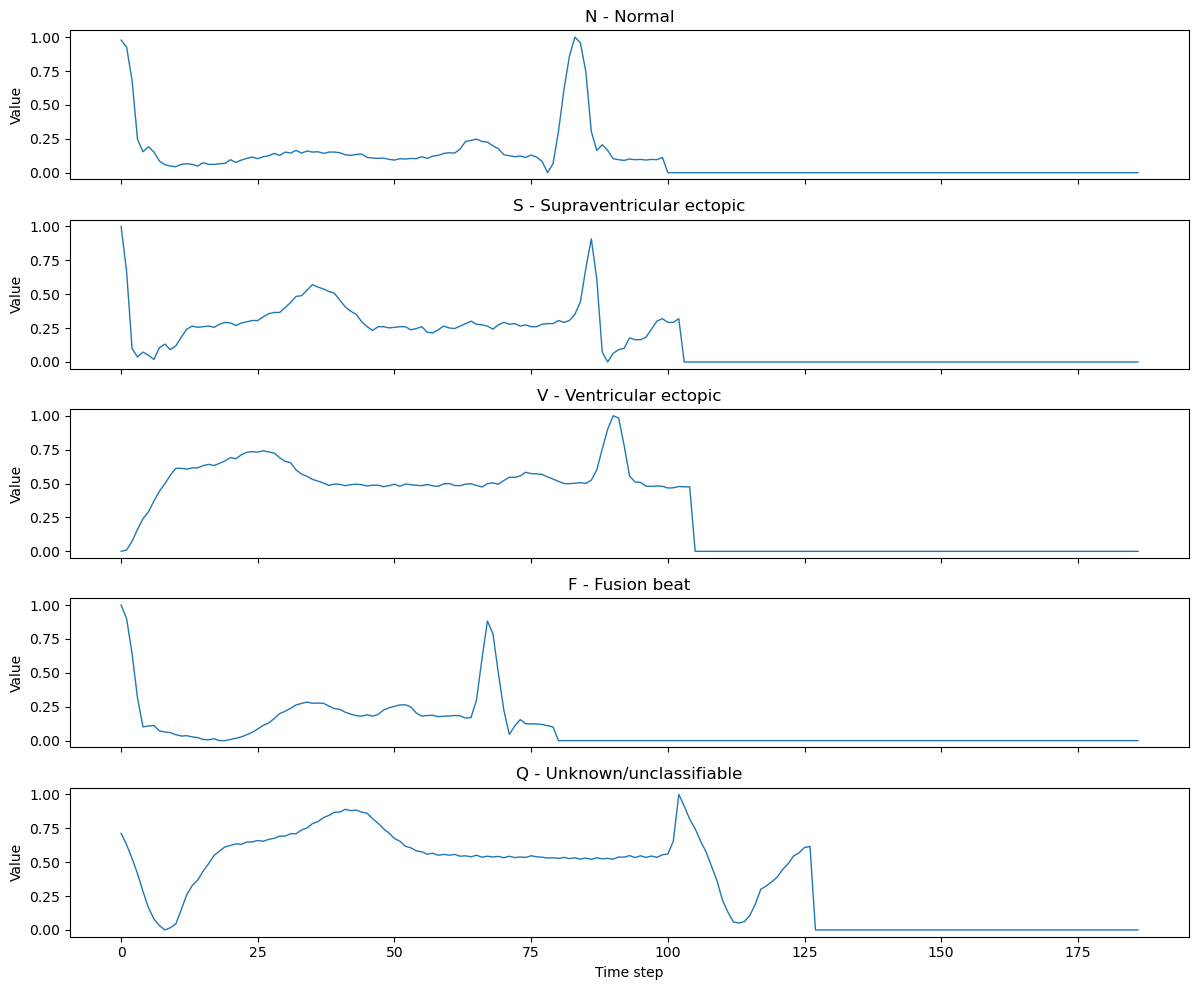

In [ ]:
fig, axes = plt.subplots(5, 1, figsize=(12, 10), sharex=True)
for class_id, ax in zip(EXPECTED_CLASSES, axes):
    candidates = train_df[train_df.iloc[:, -1].astype(int) == class_id]
    if len(candidates) == 0:
        ax.set_visible(False)
        continue
    signal = candidates.iloc[0, :-1].to_numpy(dtype=np.float32)
    ax.plot(np.arange(len(signal)), signal, linewidth=1)
    ax.set_title(CLASS_NAMES[class_id])
    ax.set_ylabel("Value")
axes[-1].set_xlabel("Time step")
plt.tight_layout()
plt.show()

## Cell 8 — Create train, validation, and test arrays

We split only the supplied training file into train and validation (80/20, stratified). The official test file is held aside until model selection is complete.

Input shape for sequence models: `(samples, 187, 1)` — 187 time steps and one signal value per step.

**Evaluation caveat:** this is a row-level split. The public preprocessed files do not provide a patient identifier in each row, so this notebook cannot guarantee patient-independent validation. Results should not be interpreted as clinical generalization.

In [ ]:
X_all = train_df.iloc[:, :-1].to_numpy(dtype=np.float32)
y_all = train_df.iloc[:, -1].to_numpy(dtype=np.int32)
X_test_2d = test_df.iloc[:, :-1].to_numpy(dtype=np.float32)
y_test = test_df.iloc[:, -1].to_numpy(dtype=np.int32)

X_train_2d, X_val_2d, y_train, y_val = train_test_split(
    X_all, y_all,
    test_size=0.20,
    random_state=SEED,
    stratify=y_all
)

# No data-fitted scaling is needed for the already preprocessed dataset.
# Add the channel dimension required by Keras sequence models.
X_train = X_train_2d[..., np.newaxis]
X_val = X_val_2d[..., np.newaxis]
X_test = X_test_2d[..., np.newaxis]

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:  ", X_val.shape, "y_val:  ", y_val.shape)
print("X_test: ", X_test.shape, "y_test: ", y_test.shape)

X_train: (70043, 187, 1) y_train: (70043,)
X_val:   (17511, 187, 1) y_val:   (17511,)
X_test:  (21892, 187, 1) y_test:  (21892,)


## Cell 9 — Class weights

Class weights make mistakes on rare classes contribute more to the training loss. They are computed from the training split only to avoid using validation/test label frequencies to set training weights. We use the same weights for every architecture for a fair comparison.

In [ ]:
classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)
CLASS_WEIGHTS = {int(c): float(w) for c, w in zip(classes, weights)}
print(CLASS_WEIGHTS)

{0: 0.2416234023837039, 1: 7.878852643419573, 2: 3.0256155507559397, 3: 27.307212475633527, 4: 2.722759961127308}


## Cell 10 — Define the four comparable models

All models receive the same input shape, use the same five-class output, optimizer, loss, class weights, train/validation split, batch size, epoch limit, and early-stopping rule. The architectures naturally have different parameter counts; record those counts when interpreting the comparison.

In [ ]:
# def build_simple_rnn():
#     model = keras.Sequential([
#         keras.Input(shape=(187, 1)),
#         layers.SimpleRNN(128),
#         layers.Dropout(0.20),
#         layers.Dense(64, activation="relu"),
#         layers.Dropout(0.19),
#         layers.Dense(5, activation="softmax"),
#     ], name="SimpleRNN")
#     return model


def build_lstm():
    model = keras.Sequential([
        keras.Input(shape=(187, 1)),
        layers.LSTM(128),
        layers.Dropout(0.20),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.20),
        layers.Dense(64, activation="relu"),
        # layers.Dropout(0.10),
        layers.Dense(5, activation="softmax"),
    ], name="LSTM")
    return model


def build_bilstm():
    model = keras.Sequential([
        keras.Input(shape=(187, 1)),
        layers.Bidirectional(layers.LSTM(128)),
        layers.Dropout(0.20),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.20),
        layers.Dense(64, activation="relu"),
        # layers.Dropout(0.10),
        layers.Dense(5, activation="softmax"),
    ], name="BiLSTM")
    return model


def build_cnn1d():
    model = keras.Sequential([
        keras.Input(shape=(187, 1)),
        layers.Conv1D(64, kernel_size=7, padding="same", activation="relu"),
        layers.MaxPooling1D(pool_size=2),
        layers.Conv1D(128, kernel_size=5, padding="same", activation="relu"),
        layers.MaxPooling1D(pool_size=2),
        layers.Conv1D(256, kernel_size=3, padding="same", activation="relu"),
        layers.GlobalAveragePooling1D(),
        layers.Dropout(0.20),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.10),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.10),
        layers.Dense(5, activation="softmax"),
    ], name="CNN1D")
    return model


MODEL_BUILDERS = {
    # "SimpleRNN": build_simple_rnn,
    "LSTM": build_lstm,
    "BiLSTM": build_bilstm,
    "CNN1D": build_cnn1d,
}

for name, builder in MODEL_BUILDERS.items():
    temp_model = builder()
    temp_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-2),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    print(f"\n{name}: {temp_model.count_params():,} parameters")


LSTM: 91,653 parameters

BiLSTM: 174,597 parameters

CNN1D: 158,853 parameters


## Cell 11 — Train all models with the same protocol

Each model gets a fresh optimizer and the same callbacks. `EarlyStopping` watches validation loss and restores the best weights. The model checkpoint is selected by validation loss, not by test performance. Training all four models may take time, especially on CPU.

In [ ]:
EPOCHS = 50
BATCH_SIZE = 128
histories = {}
trained_models = {}
training_summary = []

for name, builder in MODEL_BUILDERS.items():
    print("\n" + "=" * 70)
    print("Training:", name)
    tf.keras.backend.clear_session()

    model = builder()
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-2),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    model_path = MODEL_DIR / f"{name.lower()}_best.keras"
    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_accuracy",
            patience=10,
            restore_best_weights=True,
            verbose=1,
            mode="max"
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_accuracy",
            factor=0.9,
            patience=7,
            min_lr=1e-6,
            verbose=1,
            mode="max"
        ),
        keras.callbacks.ModelCheckpoint(
            filepath=model_path,
            monitor="val_accuracy",
            save_best_only=True,
            verbose=1,
            mode="max"
        ),
    ]

    start = time.time()
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=CLASS_WEIGHTS,
        callbacks=callbacks,
        verbose=1,
    )
    elapsed = time.time() - start

    best_model = keras.models.load_model(model_path)
    val_probs = best_model.predict(X_val, batch_size=BATCH_SIZE, verbose=0)
    val_pred = np.argmax(val_probs, axis=1)

    histories[name] = history.history
    trained_models[name] = best_model
    training_summary.append({
        "model": name,
        "parameters": best_model.count_params(),
        "epochs_run": len(history.history["loss"]),
        "training_seconds": round(elapsed, 1),
        "validation_accuracy": accuracy_score(y_val, val_pred),
        "validation_macro_f1": f1_score(
            y_val, val_pred, average="macro", zero_division=0
        ),
    })

    print(f"{name} finished in {elapsed:.1f} seconds")

summary_df = pd.DataFrame(training_summary).sort_values(
    "validation_macro_f1", ascending=False
).reset_index(drop=True)
display(summary_df)
summary_df.to_csv(ARTIFACT_DIR / "validation_model_comparison.csv", index=False)


Training: LSTM

Epoch 1/50
548/548 ━━━━━━━━━━━━━━━━━━━━ 0s 458ms/step - accuracy: 0.1180 - loss: 1.6089
Epoch 1: val_accuracy improved from None to 0.01056, saving model to artifacts\models\lstm_best.keras

Epoch 1: finished saving model to artifacts\models\lstm_best.keras
548/548 ━━━━━━━━━━━━━━━━━━━━ 282s 507ms/step - accuracy: 0.1180 - loss: 1.6089 - val_accuracy: 0.0106 - val_loss: 1.5831 - learning_rate: 0.0100
Epoch 2/50
548/548 ━━━━━━━━━━━━━━━━━━━━ 0s 476ms/step - accuracy: 0.1788 - loss: 1.5875
Epoch 2: val_accuracy improved from 0.01056 to 0.81954, saving model to artifacts\models\lstm_best.keras

Epoch 2: finished saving model to artifacts\models\lstm_best.keras
548/548 ━━━━━━━━━━━━━━━━━━━━ 289s 528ms/step - accuracy: 0.1788 - loss: 1.5875 - val_accuracy: 0.8195 - val_loss: 1.4434 - learning_rate: 0.0100
Epoch 3/50
548/548 ━━━━━━━━━━━━━━━━━━━━ 0s 469ms/step - accuracy: 0.1020 - loss: 1.5550
Epoch 3: val_accuracy did not improve from 0.81954
548/548 ━━━━━━━━━━━━━━━━━━━━ 282s 5

,model,parameters,epochs_run,training_seconds,validation_accuracy,validation_macro_f1
0,CNN1D,158853,48,5161.9,0.942094,0.787846
1,LSTM,91653,12,3661.0,0.819542,0.248074
2,BiLSTM,174597,11,8048.4,0.025413,0.009913


## Cell 12 — Compare learning curves

Training/validation loss shows optimization and overfitting behavior. Accuracy curves are also shown, but macro F1 is used later for model selection because the classes are imbalanced.

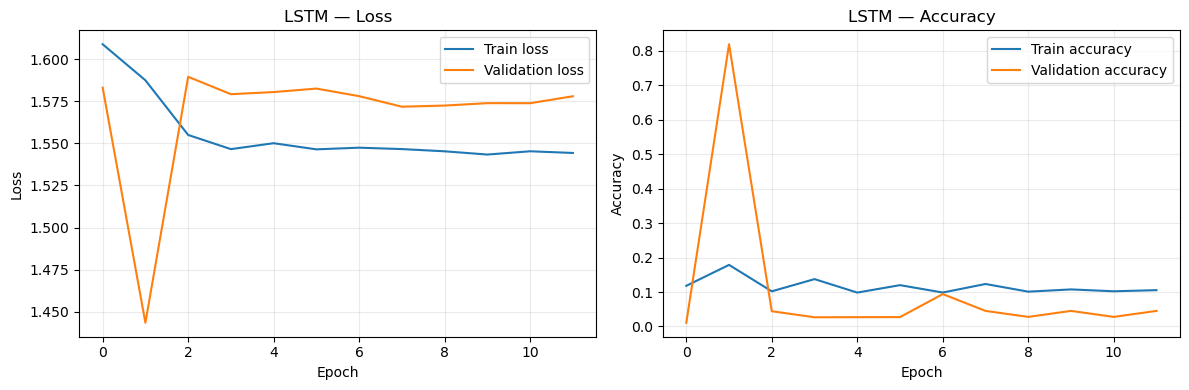

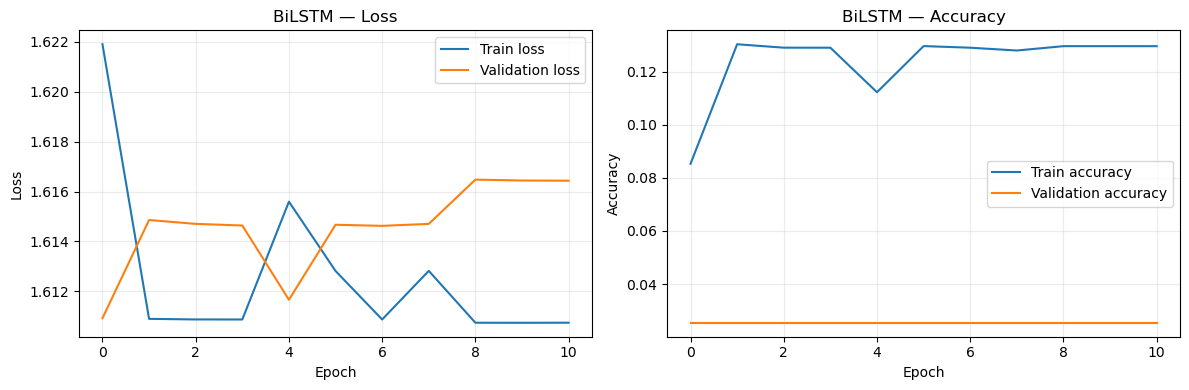

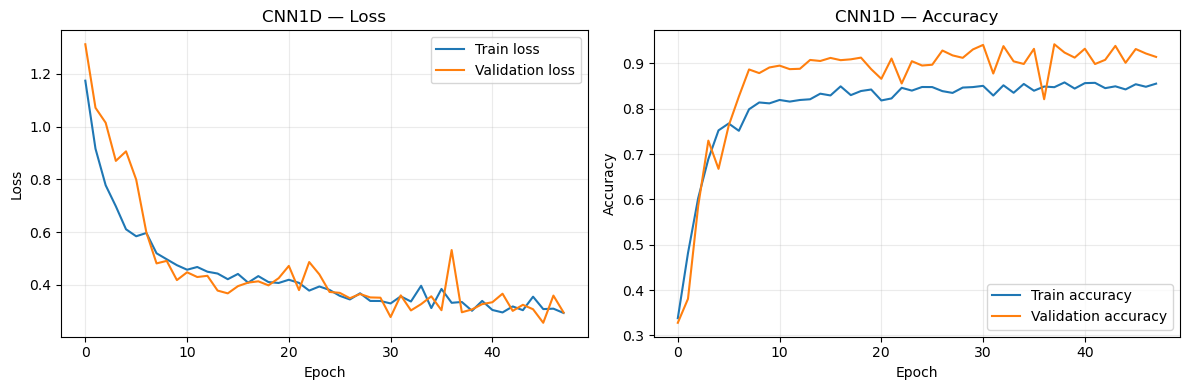

In [ ]:
for name, h in histories.items():
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(h["loss"], label="Train loss")
    axes[0].plot(h["val_loss"], label="Validation loss")
    axes[0].set_title(f"{name} — Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(alpha=0.25)

    axes[1].plot(h["accuracy"], label="Train accuracy")
    axes[1].plot(h["val_accuracy"], label="Validation accuracy")
    axes[1].set_title(f"{name} — Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(alpha=0.25)

    plt.tight_layout()
    plt.show()

## Cell 13 — Select one model using validation macro F1

The official test set must not decide which architecture wins. We select the model with the highest validation macro F1, then evaluate that chosen model once on the test set. If two models are very close, consider training variability and parameter count too.

In [ ]:
val_results = []
for name, model in trained_models.items():
    probs = model.predict(X_val, batch_size=BATCH_SIZE, verbose=0)
    pred = probs.argmax(axis=1)
    val_results.append({
        "model": name,
        "accuracy": accuracy_score(y_val, pred),
        "macro_precision": precision_score(
            y_val, pred, average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            y_val, pred, average="macro", zero_division=0
        ),
        "macro_f1": f1_score(
            y_val, pred, average="macro", zero_division=0
        ),
    })

val_results_df = pd.DataFrame(val_results).sort_values(
    "macro_f1", ascending=False
).reset_index(drop=True)
display(val_results_df)

BEST_MODEL_NAME = str(val_results_df.iloc[0]["model"])
best_model = trained_models[BEST_MODEL_NAME]
best_model.save(MODEL_DIR / "ecg_heartbeat_best.keras")

print("Selected by validation Macro F1:", BEST_MODEL_NAME)
print("Saved to:", MODEL_DIR / "ecg_heartbeat_best.keras")

,model,accuracy,macro_precision,macro_recall,macro_f1
0,CNN1D,0.942094,0.732112,0.885977,0.787846
1,LSTM,0.819542,0.248891,0.252375,0.248074
2,BiLSTM,0.025413,0.005083,0.200000,0.009913


Selected by validation Macro F1: CNN1D
Saved to: artifacts\models\ecg_heartbeat_best.keras


## Cell 14 — Final test evaluation

This is the final evaluation of the selected model on the provided test file. Do not use these results to repeatedly tune the architecture; if you change the experiment based on test performance, you should treat the test set as part of model development.

,value
selected_model,CNN1D
accuracy,0.939019
macro_precision,0.719913
macro_recall,0.870351
macro_f1,0.772847
weighted_f1,0.943528


                              precision    recall  f1-score   support

                  N - Normal       0.98      0.95      0.97     18118
S - Supraventricular ectopic       0.51      0.66      0.58       556
     V - Ventricular ectopic       0.75      0.93      0.83      1448
             F - Fusion beat       0.38      0.86      0.53       162
  Q - Unknown/unclassifiable       0.97      0.96      0.97      1608

                    accuracy                           0.94     21892
                   macro avg       0.72      0.87      0.77     21892
                weighted avg       0.95      0.94      0.94     21892



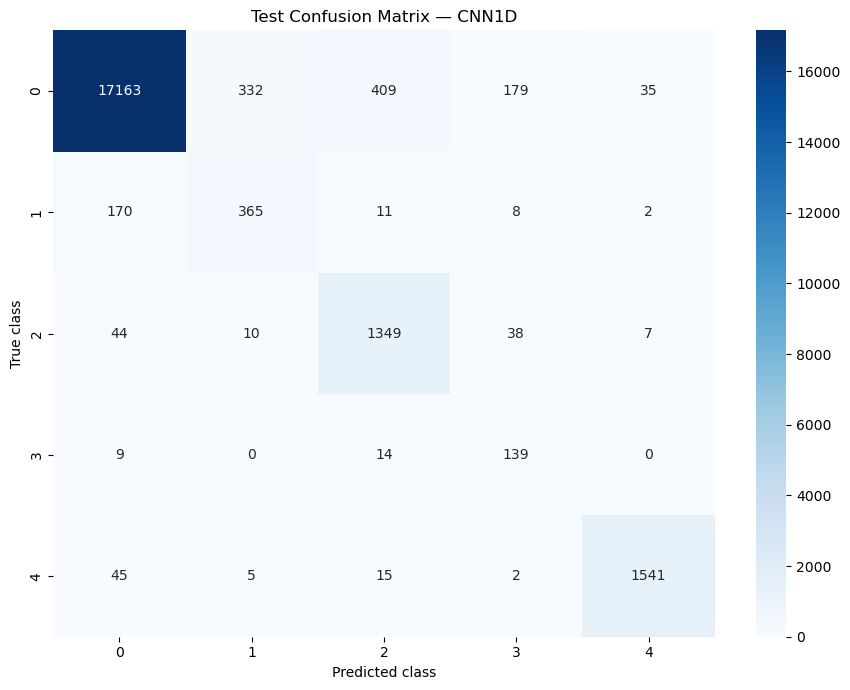

In [ ]:
test_probs = best_model.predict(X_test, batch_size=BATCH_SIZE, verbose=0)
test_pred = np.argmax(test_probs, axis=1)

test_metrics = {
    "selected_model": BEST_MODEL_NAME,
    "accuracy": accuracy_score(y_test, test_pred),
    "macro_precision": precision_score(
        y_test, test_pred, average="macro", zero_division=0
    ),
    "macro_recall": recall_score(
        y_test, test_pred, average="macro", zero_division=0
    ),
    "macro_f1": f1_score(
        y_test, test_pred, average="macro", zero_division=0
    ),
    "weighted_f1": f1_score(
        y_test, test_pred, average="weighted", zero_division=0
    ),
}
display(pd.DataFrame([test_metrics]).T.rename(columns={0: "value"}))

print(classification_report(
    y_test, test_pred,
    labels=EXPECTED_CLASSES,
    target_names=[CLASS_NAMES[i] for i in EXPECTED_CLASSES],
    zero_division=0,
))

cm = confusion_matrix(y_test, test_pred, labels=EXPECTED_CLASSES)
plt.figure(figsize=(9, 7))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=[str(i) for i in EXPECTED_CLASSES],
    yticklabels=[str(i) for i in EXPECTED_CLASSES],
)
plt.title(f"Test Confusion Matrix — {BEST_MODEL_NAME}")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.tight_layout()
plt.show()

with open(ARTIFACT_DIR / "final_test_metrics.json", "w") as f:
    json.dump(test_metrics, f, indent=2)

## Cell 15 — Compare all models on validation (not test)

This comparison is the fair model-selection table. The held-out test set above is reported only for the selected model. We deliberately avoid repeatedly checking all architectures on test data.

In [ ]:
display(
    val_results_df.style.format({
        "accuracy": "{:.4f}",
        "macro_precision": "{:.4f}",
        "macro_recall": "{:.4f}",
        "macro_f1": "{:.4f}",
    })
)

,model,accuracy,macro_precision,macro_recall,macro_f1
0,CNN1D,0.9421,0.7321,0.8860,0.7878
1,LSTM,0.8195,0.2489,0.2524,0.2481
2,BiLSTM,0.0254,0.0051,0.2000,0.0099


## Cell 16 — Save class labels and model metadata

The API and GUI need a stable label map and input shape. The API expects exactly 187 preprocessed numeric values in the same format as the dataset.

In [ ]:
metadata = {
    "model_name": BEST_MODEL_NAME,
    "input_length": 187,
    "input_features": 1,
    "classes": {str(k): v for k, v in CLASS_NAMES.items()},
    "dataset": "Kaggle ECG Heartbeat Categorization Dataset — MIT-BIH task",
    "warning": "Educational research only; not for medical diagnosis.",
}
with open(ARTIFACT_DIR / "metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print(json.dumps(metadata, indent=2))

{
  "model_name": "CNN1D",
  "input_length": 187,
  "input_features": 1,
  "classes": {
    "0": "N - Normal",
    "1": "S - Supraventricular ectopic",
    "2": "V - Ventricular ectopic",
    "3": "F - Fusion beat",
    "4": "Q - Unknown/unclassifiable"
  },
  "dataset": "Kaggle ECG Heartbeat Categorization Dataset \u2014 MIT-BIH task",
  "warning": "Educational research only; not for medical diagnosis."
}


## Cell 17 — Generate the FastAPI service (`api.py`)

This cell writes an API file that loads the exported model, validates requests, exposes `/health` and `/predict`, and automatically provides Swagger UI at `/docs`. The API uses Pydantic validation and returns clear errors for malformed signals.

In [ ]:
api_source = r"""
from pathlib import Path
import json

import numpy as np
import tensorflow as tf
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field, field_validator

BASE_DIR = Path(__file__).resolve().parent
MODEL_PATH = BASE_DIR / "artifacts" / "models" / "ecg_heartbeat_best.keras"
METADATA_PATH = BASE_DIR / "artifacts" / "metadata.json"

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Model not found at {MODEL_PATH}. Run the training notebook first."
    )

model = tf.keras.models.load_model(MODEL_PATH)
metadata = json.loads(METADATA_PATH.read_text(encoding="utf-8"))
CLASS_NAMES = {int(k): v for k, v in metadata["classes"].items()}

app = FastAPI(
    title="ECG Heartbeat Classification API",
    description=(
        "Educational five-class ECG segment classifier. "
        "Not a medical diagnostic service."
    ),
    version="1.0.0",
)

class PredictRequest(BaseModel):
    signal: list[float] = Field(
        ...,
        min_length=187,
        max_length=187,
        description="Exactly 187 preprocessed ECG values from this dataset format.",
        examples=[[0.0] * 187],
    )

    @field_validator("signal")
    @classmethod
    def check_finite(cls, values):
        arr = np.asarray(values, dtype=np.float64)
        if not np.isfinite(arr).all():
            raise ValueError("All signal values must be finite numbers.")
        return values

@app.get("/", tags=["Health"])
def root():
    return {
        "service": "ECG Heartbeat Classification API",
        "swagger_ui": "/docs",
        "health_check": "/health",
        "input_length": 187,
        "model": metadata["model_name"],
        "medical_notice": metadata["warning"],
    }

@app.get("/health", tags=["Health"])
def health():
    return {"status": "ok", "model_loaded": model is not None}

@app.post("/predict", tags=["Prediction"])
def predict(request: PredictRequest):
    try:
        x = np.asarray(request.signal, dtype=np.float32).reshape(1, 187, 1)
        probabilities = model.predict(x, verbose=0)[0]
        predicted_class = int(np.argmax(probabilities))
        return {
            "predicted_class_id": predicted_class,
            "predicted_class": CLASS_NAMES[predicted_class],
            "scores": {
                CLASS_NAMES[i]: float(probabilities[i])
                for i in range(len(probabilities))
            },
            "notice": (
                "Research prototype only. Scores are model outputs, "
                "not clinically validated probabilities or a diagnosis."
            ),
        }
    except Exception as exc:
        raise HTTPException(
            status_code=500,
            detail="Prediction failed. Check server logs for details."
        ) from exc
"""
Path("api.py").write_text(api_source.strip() + "\n", encoding="utf-8")
print("Created api.py")

Created api.py


## Cell 18 — Generate the Streamlit GUI (`app.py`)

The GUI uploads a CSV containing exactly one row of 187 signal values, draws the waveform, calls the API, and displays the predicted class and model scores. It does not accept the label column as part of the input.

In [ ]:
streamlit_source = r"""
import numpy as np
import pandas as pd
import requests
import streamlit as st
import matplotlib.pyplot as plt

st.set_page_config(
    page_title="ECG Heartbeat AI",
    page_icon="💓",
    layout="wide",
)

st.title("💓 ECG Heartbeat Classification")
st.caption("LSTM/RNN/CNN research demo — five-class MIT-BIH task")
st.warning(
    "Educational prototype only. It is not a medical diagnostic tool "
    "and must not be used for medical decisions."
)

api_url = st.sidebar.text_input(
    "FastAPI prediction endpoint",
    value="http://127.0.0.1:8000/predict",
)
uploaded = st.file_uploader(
    "Upload one CSV row with exactly 187 ECG values (no label column)",
    type=["csv"],
)

if uploaded is not None:
    try:
        frame = pd.read_csv(uploaded, header=None)
        if frame.shape != (1, 187):
            st.error(
                f"Expected shape (1, 187); received {frame.shape}. "
                "Remove the label column and upload one row only."
            )
            st.stop()

        signal = frame.iloc[0].to_numpy(dtype=np.float32)
        if not np.isfinite(signal).all():
            st.error("CSV contains NaN or infinite values.")
            st.stop()

        fig, ax = plt.subplots(figsize=(12, 3))
        ax.plot(np.arange(187), signal, linewidth=1.2)
        ax.set_title("ECG signal")
        ax.set_xlabel("Time step")
        ax.set_ylabel("Value")
        ax.grid(alpha=0.25)
        st.pyplot(fig)
        plt.close(fig)

        if st.button("Predict heartbeat class", type="primary"):
            try:
                response = requests.post(
                    api_url,
                    json={"signal": signal.tolist()},
                    timeout=30,
                )
                if response.status_code == 422:
                    st.error("The API rejected the input format.")
                    st.code(response.text)
                else:
                    response.raise_for_status()
                    result = response.json()
                    st.subheader("Prediction")
                    st.metric("Predicted class", result["predicted_class"])
                    st.subheader("Model output scores")
                    st.bar_chart(pd.Series(result["scores"]))
                    st.info(result["notice"])
            except requests.RequestException as exc:
                st.error(
                    "Cannot reach FastAPI. Start the API and check the endpoint URL."
                )
                st.caption(str(exc))
    except (ValueError, pd.errors.ParserError) as exc:
        st.error(f"Could not read the CSV: {exc}")
"""
Path("app.py").write_text(streamlit_source.strip() + "\n", encoding="utf-8")
print("Created app.py")

Created app.py


## Cell 19 — Generate `requirements.txt`

This file lists the main runtime dependencies for reproducing the project. For production, pin tested versions and use a lockfile; package compatibility can vary by operating system and Python version.

In [ ]:
requirements = """numpy
pandas
matplotlib
seaborn
scikit-learn
tensorflow
fastapi
uvicorn[standard]
streamlit
requests
"""
Path("requirements.txt").write_text(requirements, encoding="utf-8")
print(requirements)

numpy
pandas
matplotlib
seaborn
scikit-learn
tensorflow
fastapi
uvicorn[standard]
streamlit
requests



## Cell 20 — Run FastAPI and Streamlit

Run these commands in **two separate terminals** from the folder containing `api.py`, `app.py`, and `artifacts/`.

Terminal 1:
```bash
uvicorn api:app --host 127.0.0.1 --port 8000
```

Then open Swagger UI:
- http://127.0.0.1:8000/docs
- Health check: http://127.0.0.1:8000/health

Terminal 2:
```bash
streamlit run app.py
```

For local testing, `127.0.0.1` is correct. It is not publicly accessible to other people over the internet.

### Make the API public for other people

To let anyone try the API, deploy the service to a hosting provider that supports Python web apps (for example, a container host or a VM). Deploy `api.py`, `artifacts/models/ecg_heartbeat_best.keras`, and `artifacts/metadata.json`; install `requirements.txt`; then run:

```bash
uvicorn api:app --host 0.0.0.0 --port $PORT
```

The provider gives you a public HTTPS URL. Swagger will then be available at `https://YOUR-DOMAIN/docs`. Replace the placeholder with the actual URL provided by your host. Do not expose a local development server directly to the internet. Add authentication, rate limits, logging, resource limits, and privacy controls before any production deployment. Public hosting may have usage limits or costs, and this notebook cannot create or guarantee a public URL by itself.

The Streamlit app can be hosted separately; set its sidebar API endpoint to the deployed public `/predict` URL. Configure CORS only if browser-based cross-origin requests require it; the Streamlit Python server's `requests` call does not use browser CORS.

## Cell 21 — Optional: test the API from Python

Run this after starting FastAPI in another terminal. It sends one real signal from the test dataset to the local API. The signal is used only to test the service wiring, not to train or tune the model.

In [ ]:
# Optional: run only after `uvicorn api:app --reload` is running.
# This test sends a sample from the held-out test set to check API integration.
# It does NOT change model weights.

# import requests
# sample_signal = X_test_2d[0].astype(float).tolist()
# response = requests.post(
#     "http://127.0.0.1:8000/predict",
#     json={"signal": sample_signal},
#     timeout=30,
# )
# print(response.status_code)
# print(response.json())

## Final checklist and important limitations

- [ ] All four CSV files were inspected.
- [ ] The four models used the same train/validation split and evaluation rules.
- [ ] Model selection used validation macro F1, not the final test set.
- [ ] The selected model's test classification report and confusion matrix were saved.
- [ ] `artifacts/models/ecg_heartbeat_best.keras` and `artifacts/metadata.json` exist.
- [ ] `api.py` works and `/docs` is available.
- [ ] `app.py` can upload a valid 187-value signal and call the API.
- [ ] The uploaded ECG format and preprocessing match the model's training data.
- [ ] The results are described as dataset performance, not proof of clinical safety.

**Important:** a random row-level split can overestimate generalization when multiple heartbeats originate from the same patients. The provided preprocessed CSVs do not expose patient IDs in each row, so a patient-wise split cannot be performed from these files alone. Also, the API accepts preprocessed segments from this dataset format; it does not process raw ECG recordings, detect heartbeat boundaries, or replace a clinician.

### By:
AI Engineer: **Mahmoud Bassiouni**

Resume="https://drive.google.com/file/d/1AWbrExGDFs6gvlSeKoMzhoZHpXh02G2s/view?usp=drive_link"

 # **وَقُل رَّبِّ زِدْنِي عِلْمًا وَأَلْحِقْنِي بِالصَّالِحِينَ**